# Homework Module 3
<span style="color:#08519c">**13/10/2026**</span>

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
!wget $data -O course_lead_scoring_2026.csv

--2026-10-13 07:20:00--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.002s  

2026-10-13 07:20:01 (125 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



# Read the data

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
df.head(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
5,referral,manufacturing,employed,africa,43841.0,3,5,0.77,1
6,NaN,education,employed,north_america,58738.0,3,9,0.78,1
7,paid_ads,technology,employed,north_america,95059.0,2,4,0.41,1
8,organic_search,healthcare,employed,asia,62565.0,3,6,0.52,1
9,referral,retail,student,asia,12000.0,2,2,0.35,0


In [4]:
df.shape

(5000, 9)

<span style="color:red">**In this dataset our desired target for classification task will be converted variable - has the client signed up to the platform or not.**</span>

# Data preparation

In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

## Missing values

In [6]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

### For categorical features > 'NA'

In [7]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].fillna('NA')

### For numerical features > '0.0'

In [8]:
numerical_columns = list(df.select_dtypes(include=['float64', 'int64']).columns)

for c in numerical_columns:
    df[c] = df[c].fillna(0.0)

In [9]:
# Check!

In [10]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [11]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NA,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


# Question 1
What is the most frequent observation (mode) for the column industry?

In [12]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

# Question 2
Create the correlation matrix for the numerical features of your dataset. In a correlation matrix, you compute the correlation coefficient between every pair of features.

What are the two features that have the biggest correlation?

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
corr = df[numerical_columns].corr()
corr

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


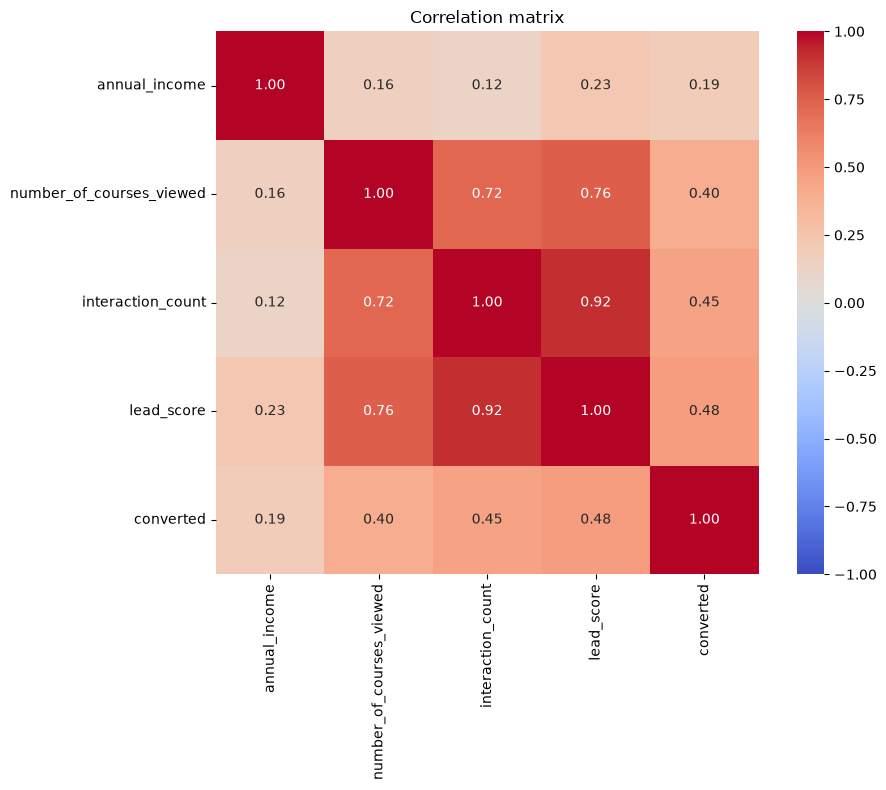

In [15]:
# Heatmap with coefficients
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,        # show the coefficients
    fmt=".2f",         # 2 decimals
    cmap="coolwarm",   # red = positive, blue = negative
    vmin=-1, vmax=1,   # fix the color scale
    center=0,
    square=True,
)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

# Split the dataset

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [18]:
df_train.reset_index(drop=True)
df_val.reset_index(drop=True)
df_test.reset_index(drop=True)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,social_media,retail,employed,south_america,41247.0,3,7,0.61,1
1,organic_search,healthcare,employed,north_america,70825.0,3,6,0.62,0
2,social_media,healthcare,employed,south_america,58488.0,3,4,0.56,1
3,NA,education,NA,europe,30138.0,1,4,0.48,0
4,NA,retail,employed,asia,53869.0,2,3,0.49,1
...,...,...,...,...,...,...,...,...,...
995,organic_search,manufacturing,employed,NA,65099.0,1,4,0.53,1
996,social_media,healthcare,student,europe,38954.0,0,0,0.15,0
997,organic_search,education,self_employed,asia,48768.0,2,5,0.47,1
998,social_media,NA,student,asia,0.0,2,2,0.35,1


In [19]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

In [20]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

<span style="color:red">**OJO: I am NOT removing 'converted' target value the df_full_train dataset as I am not sure whether it will be needed later.**</span>

# Question 3
- Calculate the mutual information score between converted and other categorical variables in the dataset. Use the training set only.
- Round the scores to 2 decimals using round(score, 2).

In [22]:
from sklearn.metrics import mutual_info_score

In [23]:
def mutual_info_converted_score(series):
    return mutual_info_score(series, y_train)

In [24]:
mi =df_train[categorical_columns].apply(mutual_info_converted_score)
round(mi.sort_values(ascending=False),2)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

# Question 4
- Now let's train a logistic regression.
- Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
- Fit the model on the training dataset.
    - To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
    - model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
- Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

What accuracy did you get?

## One-hot encoding

In [65]:
numerical_columns

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [21]:
categorical_columns

['lead_source', 'industry', 'employment_status', 'location']

<span style="color:red">**OJO: 'converted' is still there, we need to remove it.**</span>

<span style="color:red">**ALSO: I will remove categorical features which are not informative.**</span>

In [51]:
categorical_filtered = ['lead_source', 'employment_status']

In [23]:
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

In [27]:
from sklearn.feature_extraction import DictVectorizer

In [28]:
train_dicts = df_train[categorical_filtered + numerical].to_dict(orient="records")

In [29]:
dv = DictVectorizer(sparse=False)

In [30]:
dv.fit(train_dicts)

DictVectorizer(sparse=False)

In [31]:
# do directily fit & transform
X_train = dv.fit_transform(train_dicts)
X_train

array([[6.5980e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+00],
       [7.1662e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [4.0220e+04, 0.0000e+00, 1.0000e+00, ..., 1.0000e+00, 0.0000e+00,
        2.0000e+00],
       ...,
       [7.1532e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00],
       [4.8836e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [6.8969e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00]], shape=(3000, 15))

In [32]:
# same for validation dataset

In [33]:
val_dicts = df_val[categorical_filtered + numerical].to_dict(orient="records")

In [34]:
dv = DictVectorizer(sparse=False)

In [35]:
dv.fit(val_dicts)

DictVectorizer(sparse=False)

In [36]:
# do directily fit & transform
X_val = dv.transform(val_dicts)
X_val

array([[8.0457e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00],
       [7.4480e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [4.3944e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+00],
       ...,
       [6.2439e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [4.0878e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        1.0000e+00],
       [4.8769e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00]], shape=(1000, 15))

## Fit the model on the training dataset

In [37]:
from sklearn.linear_model import LogisticRegression

In [38]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The 

In [39]:
y_pred = model.predict_proba(X_val)[:, 1]
y_pred[:10]

array([0.61676123, 0.44295496, 0.60437495, 0.64499537, 0.5218877 ,
       0.77948459, 0.60717785, 0.54517601, 0.76783486, 0.52834713])

## Calculate accurac on the validation dataset

In [40]:
converted_decision = y_pred >= 0.5

In [41]:
accuracy = (y_val == converted_decision).mean()
accuracy

np.float64(0.645)

In [42]:
round(accuracy, 2)

np.float64(0.64)

# Question 5

- Let's find the least useful feature using the feature elimination technique.
- Train a model using the same features and parameters as in Q4 (without rounding).
- Now exclude each feature from this set and train a model without it. Record the accuracy for each model.
- For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of following feature has the smallest difference?

In [44]:
categorical_filtered

['lead_source', 'employment_status']

In [45]:
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [46]:
def train_and_score(features):
    dv = DictVectorizer(sparse=False)

    train_dicts = df_train[features].to_dict(orient="records")
    X_train = dv.fit_transform(train_dicts)

    val_dicts = df_val[features].to_dict(orient="records")
    X_val = dv.transform(val_dicts)          # transform only

    model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    return ((y_pred >= 0.5) == y_val).mean()



In [47]:
all_features = categorical_filtered + numerical

base_accuracy = train_and_score(all_features)
print(f"Accuracy with all features: {base_accuracy}")


Accuracy with all features: 0.645


In [48]:
results = []
for feature in all_features:
    subset = [f for f in all_features if f != feature]
    acc = train_and_score(subset)
    results.append({
        "removed_feature": feature,
        "accuracy": acc,
        "difference": base_accuracy - acc,
    })

results_df = pd.DataFrame(results).sort_values("difference", ascending=False)
results_df

,removed_feature,accuracy,difference
4,interaction_count,0.600,0.045
0,lead_source,0.642,0.003
1,employment_status,0.644,0.001
3,number_of_courses_viewed,0.644,0.001
5,lead_score,0.644,0.001
2,annual_income,0.717,-0.072


# Question 6

- Now let's train a regularized logistic regression.
- Let's try the following values of the parameter C: [0.000001, 0.00001, 0.0001, 0.001].
- Train models using all the features as in Q4.
- Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

Which of these C leads to the best accuracy on the validation set?


In [49]:
def train_and_score_REG(features, C=1.0):
    dv = DictVectorizer(sparse=False)

    train_dicts = df_train[features].to_dict(orient="records")
    X_train = dv.fit_transform(train_dicts)

    val_dicts = df_val[features].to_dict(orient="records")
    X_val = dv.transform(val_dicts)          # transform only

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    return ((y_pred >= 0.5) == y_val).mean()

In [50]:
results = []

for C in [0.000001, 0.00001, 0.0001, 0.001]:
    accuracy = train_and_score_REG(all_features, C=C)
    results.append({"C": C, "accuracy": accuracy})
    print(f"seed={C}: accuracy={accuracy}")

seed=1e-06: accuracy=0.598
seed=1e-05: accuracy=0.598
seed=0.0001: accuracy=0.613
seed=0.001: accuracy=0.645
